# Chapter 9 — Text Processing and Multiclass Classification

**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup

This notebook covers text representation, feature extraction, text classification, and multiclass evaluation. It uses a small self-contained sample corpus.

## 1. Theory: vectorizing text
Classical estimators usually require numerical features. **Bag of Words (BoW)** counts token occurrences, **TF-IDF** weights terms according to how informative they are across documents, and **n-grams** represent adjacent token sequences. For honest model evaluation, fit text vectorizers on training data only; pipelines help prevent leakage.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RANDOM_STATE = 42

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

texts = [
"football team won the match","coach trained football players","basketball team scored points",
"player made a basketball shot","software update improves computer security","computer program uses machine learning",
"software developer fixed an application bug","new processor makes computer faster",
"team practiced football before championship","basketball players trained before tournament",
"machine learning software analyzes text data","computer security protects user data",
"football coach discussed team strategy","basketball coach planned the game",
"program processes text with machine learning","computer update improves system performance",
"football player scored a goal","software application stores data securely",
"basketball is a fast team sport","machine learning classifies documents automatically",
"team won another match","developer tested the computer application",
"player practiced shooting the basketball","security software detects computer threats"
]
labels = ["sports"]*4 + ["technology"]*4 + ["sports"]*2 + ["technology"]*2 + ["sports"]*2 + ["technology"]*2 + ["sports","technology","sports","technology","sports","technology","sports","technology"]
df = pd.DataFrame({"text":texts, "category":labels})
display(df.head())
print("Documents:", len(df), "| Categories:", df.category.nunique())


,text,category
0,football team won the match,sports
1,coach trained football players,sports
2,basketball team scored points,sports
3,player made a basketball shot,sports
4,software update improves computer security,technology


Documents: 24 | Categories: 2


## 2. Compare BoW, TF-IDF, and n-grams

BoW matrix: (24, 55) | TF-IDF matrix: (24, 130)


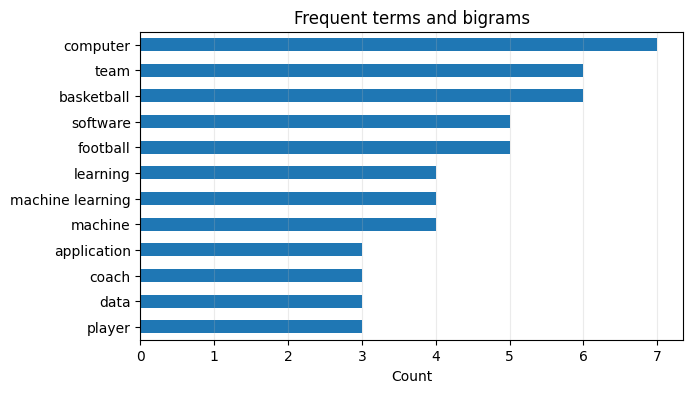

In [2]:

bow = CountVectorizer(stop_words="english")
X_bow = bow.fit_transform(df.text)
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1,2))
X_tfidf = tfidf.fit_transform(df.text)
print("BoW matrix:", X_bow.shape, "| TF-IDF matrix:", X_tfidf.shape)
ngram = CountVectorizer(stop_words="english", ngram_range=(1,2))
X_ngram = ngram.fit_transform(df.text)
freq = pd.Series(np.asarray(X_ngram.sum(axis=0)).ravel(), index=ngram.get_feature_names_out()).nlargest(12).sort_values()
freq.plot(kind="barh", figsize=(7,4))
plt.title("Frequent terms and bigrams"); plt.xlabel("Count"); plt.grid(axis="x", alpha=.25); plt.show()


## 3. Train and compare text classifiers
The vectorizer is inside each pipeline, so it is fitted on training text only.

,Test accuracy
Model,
Naive Bayes,1.0
Linear SVM,1.0
Logistic Regression,1.0


Selected model: Naive Bayes
              precision    recall  f1-score   support

      sports       1.00      1.00      1.00         3
  technology       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



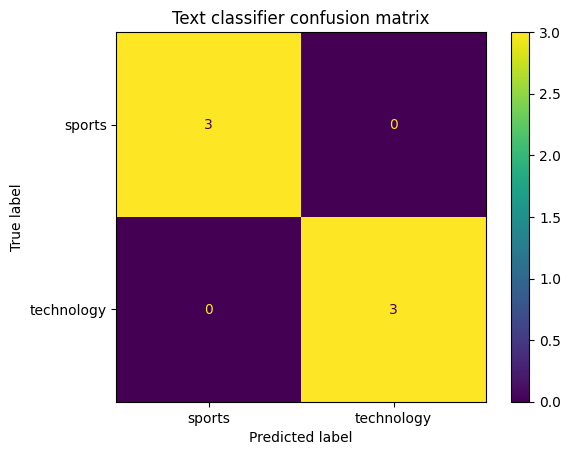

In [3]:

X_train, X_test, y_train, y_test = train_test_split(df.text, df.category, test_size=.25,
    stratify=df.category, random_state=RANDOM_STATE)
models = {
 "Naive Bayes": Pipeline([("tfidf",TfidfVectorizer(stop_words="english",ngram_range=(1,2))),("model",MultinomialNB())]),
 "Linear SVM": Pipeline([("tfidf",TfidfVectorizer(stop_words="english",ngram_range=(1,2))),("model",LinearSVC(random_state=RANDOM_STATE))]),
 "Logistic Regression": Pipeline([("tfidf",TfidfVectorizer(stop_words="english",ngram_range=(1,2))),("model",LogisticRegression(max_iter=2000,random_state=RANDOM_STATE))])
}
rows=[]
for name, model in models.items():
    model.fit(X_train,y_train)
    rows.append({"Model":name,"Test accuracy":accuracy_score(y_test,model.predict(X_test))})
display(pd.DataFrame(rows).set_index("Model").round(3))
best_name=max(models,key=lambda name:accuracy_score(y_test,models[name].predict(X_test)))
pred=models[best_name].predict(X_test)
print("Selected model:",best_name)
print(classification_report(y_test,pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=["sports","technology"])
plt.title("Text classifier confusion matrix"); plt.show()


## Exercises
1. Compare BoW and TF-IDF.
2. Change `ngram_range` from `(1,1)` to `(1,2)`.
3. Add more examples and compare model stability.
4. Inspect misclassified text and explain likely confusion.
5. Explain why vectorizers must be fitted on training data only.

## Summary
BoW counts tokens, TF-IDF emphasizes informative terms, and n-grams capture short sequences. Naive Bayes, linear SVM, and logistic regression are common text classifiers. Pipelines help prevent leakage.